In [1]:
from pathlib import Path
import json, inspect, warnings
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.table import Table
from astropy.wcs import WCS
from astropy.stats import sigma_clip, sigma_clipped_stats
from astropy.convolution import convolve_fft
from astropy.modeling.models import Sersic2D
from photutils.aperture import CircularAnnulus, CircularAperture
from photutils.segmentation import SegmentationImage, SourceCatalog, detect_sources, deblend_sources, make_2dgaussian_kernel
from photutils.centroids import centroid_2dg
from scipy import ndimage
from scipy.signal import fftconvolve

warnings.filterwarnings("ignore")
DATA, RES, FIG = Path(".."), Path("results"), Path("figures")
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 200, "font.size": 11,
                     "axes.titlesize": 12, "axes.labelsize": 11, "legend.fontsize": 9})

with fits.open(DATA / "mosaic.fits") as hdul:
    data = hdul[0].data.astype(float); header = hdul[0].header
mask = fits.getdata(RES / "mask.fits").astype(bool)
segm = fits.getdata(RES / "segmentation.fits").astype(np.int64)
with fits.open(RES / "background.fits") as h:
    bkg, rms = h[0].data.astype(float), h[1].data.astype(float)
cat = Table.read(RES / "catalogue.ecsv")
phot = Table.read(RES / "photometry.ecsv")
sdss = Table.read(DATA / "sdss_stars.csv", format="ascii.csv", comment="#")
GAIN = float(header.get("GAIN", 3.1)); SAT = float(header["SATURATE"])
AP_FRAC = float(phot.meta["AP_FRAC"])
ny, nx = data.shape

In [2]:
SKY_LEVEL = 3418.5                 # approximate sky, used only when centring stars
SAT_FRAC = 0.8                     # reject stars peaking above 80% of saturation
ZP_STAR_RANGE = (17.0, 20.0)       # SDSS r range used for the aperture zero point
KRON_STAR_RANGE = (19.0, 21.5)
EDGE_ZONE_PX = 450                 # "edge" zone = within 450 px of the image edge
INJ_MAGS = np.arange(21.0, 26.01, 0.5)
INJ_PER_MAG, INJ_MIN_SEP = 300, 60.0
MATCH_RADIUS = 3.0
SIZE_SAMPLE_RANGE = (21.0, 23.5)
SERSIC_N, OVERSAMPLE = 1.0, 5      # fake galaxies: exponential discs
BIAS_MIN_COMPLETENESS = 0.8
CORR = 1.88                        # correlated-noise factor (notebook 3)

# photometry settings (as notebook 3)
R_AP, R_IN, R_OUT, R_OUT_STEP, R_OUT_MAX, MIN_SKY_PIX, SEG_GROW = 6.0, 15.0, 25.0, 10.0, 55.0, 60, 8
FLAG_MASKED, FLAG_NEIGHBOUR, FLAG_SKY, FLAG_NONPOSITIVE, FLAG_EDGE = 1, 2, 4, 8, 16

In [3]:
def robust(v):
    """median, robust sigma (from the median absolute deviation) and error of the median"""
    v = np.asarray(v, float); med = float(np.median(v)); sig = float(1.4826 * np.median(np.abs(v - med)))
    return med, sig, float(1.2533 * sig / np.sqrt(len(v)))


def photometry(image, mask_map, segm_map, xs, ys, labels, corr=CORR, gain=GAIN):
    not_sky = mask_map | ndimage.binary_dilation(segm_map > 0, iterations=SEG_GROW)
    out = []
    for x, y, lab in zip(np.asarray(xs, float), np.asarray(ys, float), np.asarray(labels, int)):
        r_out, widened = R_OUT, False
        while True:
            ann = CircularAnnulus((x, y), R_IN, r_out).to_mask(method="center")
            vals = ann.cutout(image, fill_value=np.nan)
            use = (ann.data > 0) & ~(ann.cutout(not_sky.astype(float), fill_value=1.0) > 0) & np.isfinite(vals)
            if use.sum() >= MIN_SKY_PIX or r_out >= R_OUT_MAX:
                break
            r_out += R_OUT_STEP; widened = True
        if use.sum() < 5:
            sky, sky_std, n_sky, sky_bad = np.nan, np.nan, int(use.sum()), True
        else:
            c = sigma_clip(vals[use], sigma=3.0, maxiters=10, masked=False)
            sky, sky_std, n_sky, sky_bad = float(np.median(c)), float(np.std(c)), int(c.size), widened or use.sum() < MIN_SKY_PIX
        ap = CircularAperture((x, y), R_AP).to_mask(method="exact"); w = ap.data
        v = ap.cutout(image, fill_value=np.nan); m = ap.cutout(mask_map.astype(float), fill_value=1.0) > 0
        sg = ap.cutout(segm_map, fill_value=0); off = bool(np.any(~np.isfinite(v) & (w > 0)))
        nb = (sg > 0) & (sg != lab)
        v = np.where(m | nb, sky, np.where(np.isfinite(v), v, sky))
        f, area = float((w * (v - sky)).sum()), float(w.sum())
        fm, fn = float((w * m).sum() / area), float((w * (nb & ~m)).sum() / area)
        err = float(np.sqrt(max(f, 0) / gain + corr ** 2 * area * sky_std ** 2 + corr ** 2 * area ** 2 * sky_std ** 2 / max(n_sky, 1)))
        flag = FLAG_MASKED * (fm > 0) | FLAG_NEIGHBOUR * (fn > 0.1) | FLAG_SKY * sky_bad | FLAG_NONPOSITIVE * (not f > 0) | FLAG_EDGE * off
        out.append((f, err, int(flag)))
    return np.array([o[0] for o in out]), np.array([o[1] for o in out]), np.array([o[2] for o in out])


def kw(func, **kwargs):
    params = inspect.signature(func).parameters
    alias = {"n_pixels": "npixels", "n_levels": "nlevels"}
    return {(k if k in params else alias[k]): v for k, v in kwargs.items() if k in params or alias.get(k) in params}


def get_col(cat, *names):
    for n in names:
        if hasattr(type(cat), n):
            v = getattr(cat, n); return np.asarray(getattr(v, "value", v), float)
    raise AttributeError(names)


def detect(image, mask_map):
    """Notebook 2 detection, with the background map fixed to the real image's one."""
    sub = image - bkg
    conv = convolve_fft(np.where(mask_map, 0.0, sub), make_2dgaussian_kernel(4.0, size=9), normalize_kernel=True, allow_huge=True)
    good = ~mask_map & (rms > 0)
    ratio = float(sigma_clipped_stats(conv[good] / rms[good], sigma=3.0, maxiters=10)[2])
    s = detect_sources(conv, 4.0 * ratio * rms, mask=mask_map, **kw(detect_sources, n_pixels=8))
    extra = {"progress_bar": False} if "progress_bar" in inspect.signature(deblend_sources).parameters else {}
    s = deblend_sources(conv, s, contrast=0.005, **kw(deblend_sources, n_pixels=8, n_levels=32), **extra)
    sc = SourceCatalog(sub, s, mask=mask_map, convolved_data=conv)
    return get_col(sc, "x_centroid", "xcentroid"), get_col(sc, "y_centroid", "ycentroid"), get_col(sc, "label").astype(int), s, sub


def zone_of(x, y):
    d = np.minimum.reduce([np.asarray(x), nx - 1 - np.asarray(x), np.asarray(y), ny - 1 - np.asarray(y)])
    return np.where(d < EDGE_ZONE_PX, "edge", "inner")

In [4]:
data_sub = data - bkg
kron = get_col(SourceCatalog(data_sub, SegmentationImage(segm), mask=mask), "kron_flux")


def centroid_star(x, y, half):
    a, b = int(round(x)), int(round(y))
    cut = data[b - half:b + half + 1, a - half:a + half + 1] - SKY_LEVEL
    if cut.shape != (2 * half + 1, 2 * half + 1) or cut.max() < 150:
        return np.nan, np.nan, np.nan
    cx, cy = centroid_2dg(cut)
    return cx + a - half, cy + b - half, cut.max() + SKY_LEVEL


x0, y0 = WCS(header).all_world2pix(sdss["ra"], sdss["dec"], 0)
first = np.array([centroid_star(a, b, 10) for a, b in zip(x0, y0)])
final = np.array([centroid_star(a, b, 6) if np.isfinite(a) else (np.nan,) * 3 for a, b in zip(first[:, 0], first[:, 1])])
xs, ys, peak = final.T
ok = np.isfinite(xs) & (xs > 160) & (xs < nx - 160) & (ys > 160) & (ys < ny - 160) & (np.hypot(xs - x0, ys - y0) < 10)
xi, yi = np.where(ok, np.round(xs), 0).astype(int), np.where(ok, np.round(ys), 0).astype(int)
ok &= ~mask[yi, xi]
f_st, _, flag_st = photometry(data, mask, segm, xs[ok], ys[ok], segm[yi[ok], xi[ok]])
r_sdss = np.asarray(sdss["psfMag_r"])[ok]
clean = ((flag_st & ~FLAG_MASKED) == 0) & (f_st > 0) & (peak[ok] < SAT_FRAC * SAT)
use = clean & (r_sdss > ZP_STAR_RANGE[0]) & (r_sdss < ZP_STAR_RANGE[1])
zp_vals = r_sdss[use] + 2.5 * np.log10(f_st[use])
ZP_AP, ZP_AP_SIG, ZP_AP_ERR = robust(zp_vals)

cx, cy = np.asarray(cat["x"]), np.asarray(cat["y"])
kron_vals, kron_r = [], []
for a, b, rr, pk in zip(xs[ok], ys[ok], r_sdss, peak[ok]):
    d = np.hypot(cx - a, cy - b); j = int(np.argmin(d))
    if d[j] < 2 and phot["flag"][j] == 0 and kron[j] > 0 and pk < SAT_FRAC * SAT and KRON_STAR_RANGE[0] < rr < KRON_STAR_RANGE[1]:
        kron_vals.append(rr + 2.5 * np.log10(kron[j])); kron_r.append(rr)
ZP_KRON, ZP_KRON_SIG, ZP_KRON_ERR = robust(kron_vals)
print(f"aperture zero point ZP_ap   = {ZP_AP:.3f} +- {ZP_AP_ERR:.3f}  ({use.sum()} stars, scatter {ZP_AP_SIG:.3f})")
print(f"Kron zero point     ZP_kron = {ZP_KRON:.3f} +- {ZP_KRON_ERR:.3f}  ({len(kron_vals)} stars, scatter {ZP_KRON_SIG:.3f})")
print(f"for comparison, lab MAGZPT + 2.5 log10(EXPTIME) = {header['MAGZPT'] + 2.5 * np.log10(header['EXPTIME']):.3f}")

aperture zero point ZP_ap   = 32.309 +- 0.014  (11 stars, scatter 0.036)
Kron zero point     ZP_kron = 32.489 +- 0.015  (52 stars, scatter 0.086)
for comparison, lab MAGZPT + 2.5 log10(EXPTIME) = 32.443


In [5]:
ok_s = (cat["snr"] > 80) & (cat["ellipticity"] < 0.1) & (cat["peak"] < 20000) & ~np.asarray(cat["near_mask"], bool)
cand = cat[ok_s]
keep = [i for i, (a, b) in enumerate(zip(cand["x"], cand["y"])) if np.sum(np.hypot(cx - a, cy - b) < 30) == 1]
psf_stars = cand[keep]; psf_stars.sort("fwhm"); psf_stars = psf_stars[:40]
not_sky = mask | ndimage.binary_dilation(segm > 0, iterations=SEG_GROW)
half = 25
gy, gx = np.mgrid[-half:half + 1, -half:half + 1]
inside = np.hypot(gx, gy) <= 20
stack = []
for a, b in zip(psf_stars["x"], psf_stars["y"]):
    ai, bi = int(round(a)), int(round(b))
    cut = data[bi - half:bi + half + 1, ai - half:ai + half + 1]
    if cut.shape != gx.shape:
        continue
    ann = CircularAnnulus((a, b), 25, 40).to_mask(method="center")
    vals = ann.cutout(data, fill_value=np.nan)
    u = (ann.data > 0) & ~(ann.cutout(not_sky.astype(float), fill_value=1.0) > 0) & np.isfinite(vals)
    if u.sum() < MIN_SKY_PIX:
        continue
    s = float(np.median(sigma_clip(vals[u], sigma=3.0, maxiters=10, masked=False)))
    c = ndimage.shift(cut - s, (bi - b, ai - a), order=3, mode="nearest")
    if c[inside].sum() > 0:
        stack.append(c / c[inside].sum())
psf = np.median(np.array(stack), axis=0); psf /= psf[inside].sum()
rr = np.hypot(gx, gy).ravel(); order = np.argsort(rr)
PSF_R50 = float(rr[order][np.searchsorted(np.cumsum(psf.ravel()[order]) / psf.sum(), 0.5)])

with np.errstate(divide="ignore", invalid="ignore"):
    r_point = ZP_AP - 2.5 * np.log10(np.asarray(phot["ap_flux"]))
sc = SourceCatalog(data_sub, SegmentationImage(segm), mask=mask)
r50 = np.asarray(getattr(sc.fluxfrac_radius(0.5), "value", sc.fluxfrac_radius(0.5)), float)
q_all = 1 - get_col(sc, "ellipticity")
sel = (r_point > SIZE_SAMPLE_RANGE[0]) & (r_point < SIZE_SAMPLE_RANGE[1]) & np.isfinite(r50) & (r50 > 1.15 * PSF_R50)
sizes = np.sqrt(np.clip(r50[sel] ** 2 - PSF_R50 ** 2, 0.25, None)); qs = np.clip(q_all[sel], 0.2, 1.0)
print(f"PSF built from {len(stack)} stars, half-light radius {PSF_R50:.2f} px; "
      f"{len(sizes)} real galaxies give intrinsic sizes, median {np.median(sizes):.2f} px")

PSF built from 35 stars, half-light radius 4.12 px; 223 real galaxies give intrinsic sizes, median 3.36 px


In [6]:
def sersic_stamp(r_e, q, pa):
    h = int(np.ceil(max(6 * r_e, 4) + psf.shape[0] // 2)); size = 2 * h + 1
    fine = np.linspace(-h - 0.5 + 0.5 / OVERSAMPLE, h + 0.5 - 0.5 / OVERSAMPLE, size * OVERSAMPLE)
    fx, fy = np.meshgrid(fine, fine)
    img = Sersic2D(amplitude=1.0, r_eff=r_e, n=SERSIC_N, x_0=0, y_0=0, ellip=1 - q, theta=pa)(fx, fy)
    img = img.reshape(size, OVERSAMPLE, size, OVERSAMPLE).sum(axis=(1, 3)); img /= img.sum()
    img = np.clip(fftconvolve(img, psf / psf.sum(), mode="same"), 0, None)
    return img / img.sum()


def add_stamp(image, x, y, stamp, flux, rng):
    h = stamp.shape[0] // 2; xi, yi = int(round(x)), int(round(y))
    shifted = ndimage.shift(stamp, (y - yi, x - xi), order=1, mode="constant") * flux
    noisy = rng.poisson(np.clip(shifted, 0, None) * GAIN) / GAIN
    y0_, x0_ = yi - h, xi - h
    sl = (slice(max(0, y0_), min(ny, y0_ + stamp.shape[0])), slice(max(0, x0_), min(nx, x0_ + stamp.shape[1])))
    image[sl] += noisy[sl[0].start - y0_:sl[0].stop - y0_, sl[1].start - x0_:sl[1].stop - x0_]


rng = np.random.default_rng(11)
allowed = ~ndimage.binary_dilation(mask, iterations=10)
rows = []
for m_in in INJ_MAGS:
    flux_in = 10 ** ((ZP_AP - m_in) / 2.5) / AP_FRAC           # total counts for a galaxy of magnitude m_in
    pts = []
    while len(pts) < INJ_PER_MAG:
        x, y = rng.uniform(60, nx - 60), rng.uniform(60, ny - 60)
        if allowed[int(y), int(x)] and all(np.hypot(x - a, y - b) > INJ_MIN_SEP for a, b, *_ in pts):
            j = rng.integers(len(sizes))
            pts.append((x, y, sizes[j], qs[j], rng.uniform(0, np.pi)))
    img = data.copy()
    for x, y, re, q, pa in pts:
        add_stamp(img, x, y, sersic_stamp(re, q, pa), flux_in, rng)
    dx, dy, dlab, dsegm, dsub = detect(img, mask)
    kron_i = get_col(SourceCatalog(dsub, dsegm, mask=mask), "kron_flux")
    pxy = np.array([(p[0], p[1]) for p in pts])
    idx = np.full(len(pts), -1)
    for i, (x, y) in enumerate(pxy):
        d = np.hypot(dx - x, dy - y); j = int(np.argmin(d))
        if d[j] <= MATCH_RADIUS:
            idx[i] = j
    found = idx >= 0
    f_inj, _, _ = photometry(img, mask, dsegm.data, dx[idx[found]], dy[idx[found]], dlab[idx[found]])
    with np.errstate(divide="ignore", invalid="ignore"):
        m_ap = ZP_AP - 2.5 * np.log10(f_inj); m_kr = ZP_KRON - 2.5 * np.log10(kron_i[idx[found]])
    zones = zone_of(pxy[:, 0], pxy[:, 1]); k = 0
    for i in range(len(pts)):
        row = {"mag_in": float(m_in), "x": pxy[i, 0], "y": pxy[i, 1], "r_e": pts[i][2], "zone": str(zones[i]), "found": bool(found[i]), "m_ap": np.nan, "m_kron": np.nan}
        if found[i]:
            row["m_ap"], row["m_kron"] = float(m_ap[k]), float(m_kr[k]); k += 1
        rows.append(row)
    print(f"  fake galaxies at r = {m_in:5.2f}: {100 * found.mean():.0f}% recovered")
inj = Table(rows=rows)
inj.write(RES / "injected_galaxies.ecsv", overwrite=True)

  fake galaxies at r = 21.00: 99% recovered


  fake galaxies at r = 21.50: 97% recovered


  fake galaxies at r = 22.00: 95% recovered


  fake galaxies at r = 22.50: 94% recovered


  fake galaxies at r = 23.00: 91% recovered


  fake galaxies at r = 23.50: 85% recovered


  fake galaxies at r = 24.00: 76% recovered


  fake galaxies at r = 24.50: 36% recovered


  fake galaxies at r = 25.00: 9% recovered


  fake galaxies at r = 25.50: 1% recovered


  fake galaxies at r = 26.00: 3% recovered


In [7]:
comp_rows, tr_rows = [], []
for m in np.unique(inj["mag_in"]):
    at = inj[inj["mag_in"] == m]
    for zone in ("inner", "edge", "all"):
        z = at if zone == "all" else at[at["zone"] == zone]
        c = float(np.mean(z["found"])) if len(z) else np.nan
        comp_rows.append({"mag": float(m), "zone": zone, "n": len(z), "C": c,
                          "C_err": float(np.sqrt(c * (1 - c) / len(z))) if len(z) else np.nan})
    f = at[at["found"]]; row = {"mag_in": float(m), "n_found": len(f)}
    for est in ("m_ap", "m_kron"):
        d = np.asarray(f[est]) - m; d = d[np.isfinite(d)]
        med, sig, err = robust(d) if len(d) >= 5 else (np.nan,) * 3
        row.update({f"{est}_bias": med, f"{est}_bias_err": err, f"{est}_scatter": sig})
    tr_rows.append(row)
comp, transfer = Table(rows=comp_rows), Table(rows=tr_rows)


def limit_at(zone, level):
    c = comp[comp["zone"] == zone]; m, cv = np.asarray(c["mag"]), np.asarray(c["C"])
    below = np.where(cv < level)[0]
    if len(below) == 0:
        return float(m[-1])
    i = below[0]
    return float(m[0]) if i == 0 else float(np.interp(level, [cv[i], cv[i - 1]], [m[i], m[i - 1]]))


LIM90, LIM50 = limit_at("all", 0.9), limit_at("all", 0.5)
good_m = np.asarray(transfer["mag_in"]) <= LIM90
score = {e: float(np.sqrt(np.nanmean(np.asarray(transfer[f"{e}_bias"])[good_m] ** 2 + np.asarray(transfer[f"{e}_scatter"])[good_m] ** 2)))
         for e in ("m_ap", "m_kron")}
BEST = min(score, key=score.get)
print(f"90% complete to r = {LIM90:.2f}, 50% complete to r = {LIM50:.2f}")
print(f"rms magnitude error for galaxies: aperture {score['m_ap']:.3f}, Kron {score['m_kron']:.3f} -> use {BEST}")
comp.write(RES / "completeness.ecsv", overwrite=True); transfer.write(RES / "magnitude_transfer.ecsv", overwrite=True)

90% complete to r = 23.11, 50% complete to r = 24.33
rms magnitude error for galaxies: aperture 0.352, Kron 0.183 -> use m_kron


In [8]:
with np.errstate(divide="ignore", invalid="ignore"):
    r_kron = ZP_KRON - 2.5 * np.log10(kron)
r_raw = r_point if BEST == "m_ap" else r_kron
bias_curve, m_curve = np.asarray(transfer[f"{BEST}_bias"]), np.asarray(transfer["mag_in"])
c_all = comp[comp["zone"] == "all"]
c_at = np.interp(m_curve, np.asarray(c_all["mag"]), np.asarray(c_all["C"]))
okc = np.isfinite(bias_curve) & (c_at >= BIAS_MIN_COMPLETENESS)
bias_here = np.interp(r_raw, m_curve[okc], bias_curve[okc])
out = Table({"label": phot["label"], "x": phot["x"], "y": phot["y"], "zone": zone_of(phot["x"], phot["y"]),
             "r_point": r_point, "r_point_err": phot["mag_ap_err"], "r_kron_raw": r_kron, "r_gal": r_raw - bias_here,
             "r_gal_bias_applied": bias_here, "beyond_90pc_complete": (r_raw - bias_here) > LIM90, "flag": phot["flag"]})
out.meta.update({"ZP_ap": ZP_AP, "ZP_ap_err": ZP_AP_ERR, "ZP_kron": ZP_KRON, "galaxy_estimator": BEST,
                 "r90": LIM90, "r50": LIM50})
out.write(RES / "calibrated_catalogue.ecsv", overwrite=True)
json.dump({"ZP_ap": ZP_AP, "ZP_ap_err": ZP_AP_ERR, "n_ap": int(use.sum()), "ZP_kron": ZP_KRON, "ZP_kron_err": ZP_KRON_ERR,
           "r90": LIM90, "r50": LIM50, "galaxy_estimator": BEST, "estimator_rms": score},
          open(RES / "calibration_summary.json", "w"), indent=1)

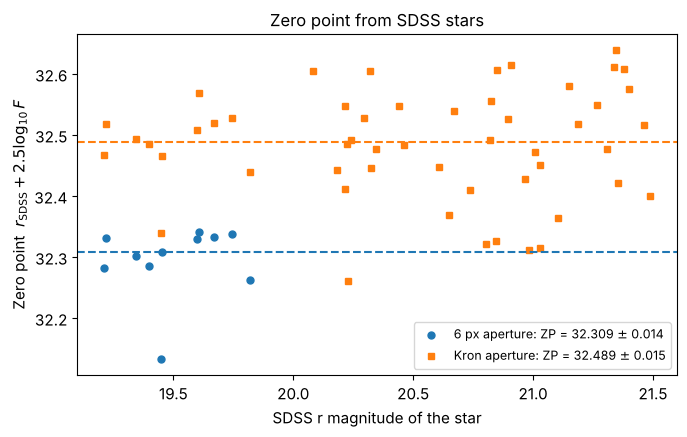

In [9]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(r_sdss[use], zp_vals, "o", ms=5, label=f"6 px aperture: ZP = {ZP_AP:.3f} $\\pm$ {ZP_AP_ERR:.3f}")
ax.plot(kron_r, kron_vals, "s", ms=5, label=f"Kron aperture: ZP = {ZP_KRON:.3f} $\\pm$ {ZP_KRON_ERR:.3f}")
ax.axhline(ZP_AP, color="C0", ls="--"); ax.axhline(ZP_KRON, color="C1", ls="--")
ax.set_xlabel("SDSS r magnitude of the star"); ax.set_ylabel(r"Zero point  $r_{\rm SDSS} + 2.5\log_{10}F$")
ax.set_title("Zero point from SDSS stars"); ax.legend()
fig.tight_layout(); fig.savefig(FIG / "04_zero_point.png"); plt.show()

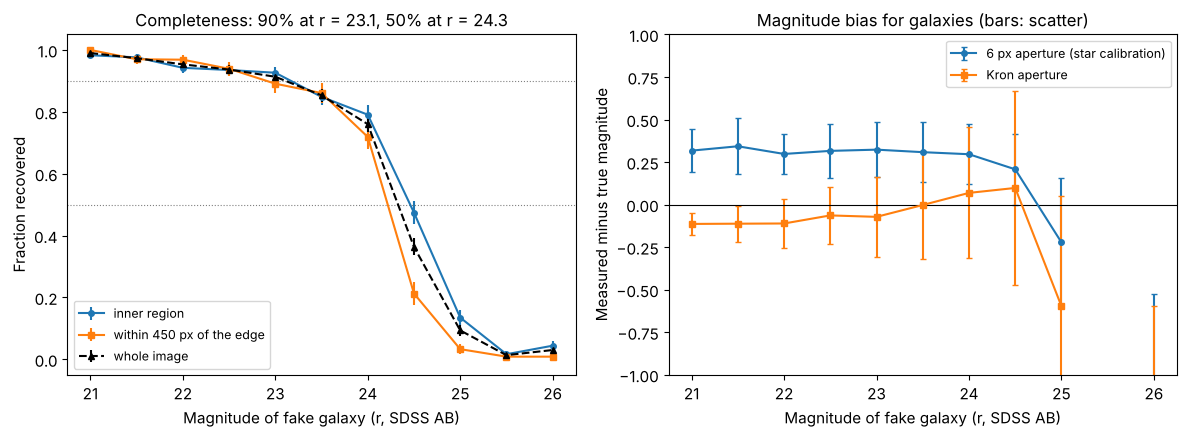

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for zone, style, lab in (("inner", "o-", "inner region"), ("edge", "s-", "within 450 px of the edge"), ("all", "k^--", "whole image")):
    c = comp[comp["zone"] == zone]
    axes[0].errorbar(c["mag"], c["C"], c["C_err"], fmt=style, ms=4, label=lab)
for lvl in (0.9, 0.5):
    axes[0].axhline(lvl, color="grey", ls=":", lw=0.8)
axes[0].set_xlabel("Magnitude of fake galaxy (r, SDSS AB)"); axes[0].set_ylabel("Fraction recovered")
axes[0].set_title(f"Completeness: 90% at r = {LIM90:.1f}, 50% at r = {LIM50:.1f}"); axes[0].legend()
for est, lab, style in (("m_ap", "6 px aperture (star calibration)", "o-"), ("m_kron", "Kron aperture", "s-")):
    axes[1].errorbar(transfer["mag_in"], transfer[f"{est}_bias"], transfer[f"{est}_scatter"], fmt=style, ms=4, capsize=2, label=lab)
axes[1].axhline(0, color="k", lw=0.8); axes[1].set_ylim(-1, 1)
axes[1].set_xlabel("Magnitude of fake galaxy (r, SDSS AB)"); axes[1].set_ylabel("Measured minus true magnitude")
axes[1].set_title("Magnitude bias for galaxies (bars: scatter)"); axes[1].legend()
fig.tight_layout(); fig.savefig(FIG / "04_completeness_and_bias.png"); plt.show()